# 02 · Valores faltantes y atípicos

**Etapa 02 del pipeline** (transformación). Limpieza de nivel 3: comprueba la exactitud y la existencia de los
valores. Para cada columna con faltantes se diagnostica **por qué falta** antes de decidir qué hacer, y cada
atípico se clasifica como error o como extremo plausible.

| | Archivo |
| --- | --- |
| Entrada | `data/intermedio/01_homeoffice_limpio.csv` |
| Salida | `data/intermedio/02_homeoffice_tratado.csv` |
| Evidencia | `data/evidencia/02_correcciones.csv`, `02_atipicos.csv`, `02_excluidos_por_error.csv` |

**Técnicas del curso**: detección de faltantes y sus tipos MCAR, MAR y MNAR con `crosstab` y
`chi2_contingency` (U3_L3, U3_T2); estrategias de manejo —ignorar, eliminar filas, eliminar columnas, estimar e
imputar— (U3_L4); atípicos univariados con IQR, z-score, boxplot e histograma, bivariados con diagramas de
dispersión y multivariados con K-Means y Mahalanobis, y sus cuatro tratamientos (U3_L5, U3_T3).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML
from scipy.stats import chi2, chi2_contingency
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import comun
from comun import (INTERMEDIO, SEMILLA, escribir_csv, guardar_evidencia, guardar_figura, registrar,
                   registrar_balance, soles)

comun.aplicar_estilo()
ho = pd.read_csv(INTERMEDIO / '01_homeoffice_limpio.csv', parse_dates=['fecha_extraccion'],
                 dtype={'id_oferta': 'string', 'vendedor': 'string', 'envio': 'string', 'etiqueta_texto': 'string'})
for c in ['descuento_anunciado_pct', 'numero_cuotas', 'vendidos_min']:
    ho[c] = ho[c].astype('Int64')
assert ho['id_oferta'].is_unique, 'Entrada inválida: id_oferta repetido (invariante de unicidad)'
N_ENTRADA = len(ho)
print(ho.shape)

(2715, 20)


## 1. Detección de valores faltantes (FR-006)

In [2]:
faltantes = ho.isna().mean().mul(100).round(2)
faltantes = faltantes[faltantes > 0].sort_values(ascending=False).rename('% faltante').to_frame()
faltantes['filas'] = ho[faltantes.index].isna().sum()
faltantes

,% faltante,filas
etiqueta_texto,100.00,2715
calificacion,63.79,1732
vendidos_min,63.13,1714
vendedor,56.35,1530
precio_anterior,43.65,1185
descuento_anunciado_pct,43.65,1185
envio,6.37,173
numero_cuotas,2.10,57
monto_cuota,2.10,57


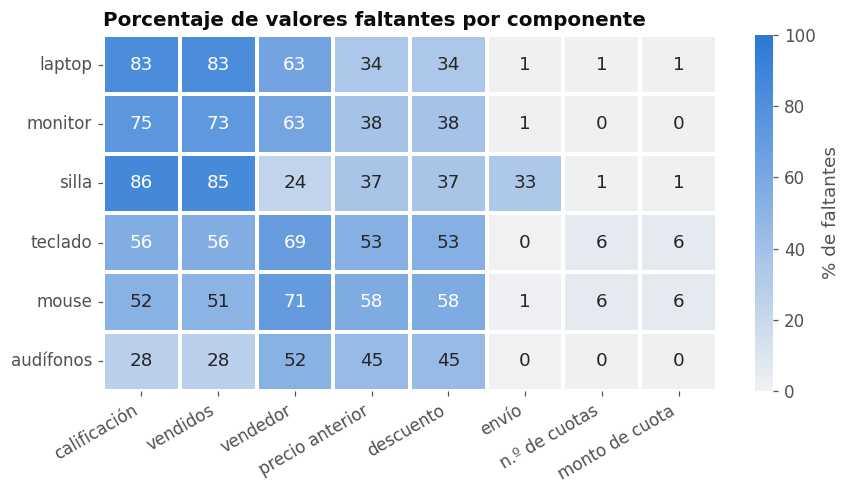

Lectura: No. El faltante de reseñas va de 28 % a 86 % según el componente y el de vendedor de 24 % a 71 %; el máximo es calificación en silla (86 %). Un faltante que depende del componente no es aleatorio, por eso no se pueden borrar esas filas sin sesgar la muestra.


In [3]:
ETIQUETAS = {'calificacion': 'calificación', 'vendidos_min': 'vendidos', 'vendedor': 'vendedor',
             'precio_anterior': 'precio anterior', 'descuento_anunciado_pct': 'descuento', 'envio': 'envío',
             'numero_cuotas': 'n.º de cuotas', 'monto_cuota': 'monto de cuota'}
por_componente = (ho.groupby('componente')[list(ETIQUETAS)].apply(lambda g: g.isna().mean() * 100)
                  .reindex(comun.ORDEN_COMPONENTES).rename(columns=ETIQUETAS, index={'audifonos': 'audífonos'}))
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.heatmap(por_componente, annot=True, fmt='.0f', cmap=sns.light_palette('#2a78d6', as_cmap=True),
            vmin=0, vmax=100, cbar_kws={'label': '% de faltantes'}, linewidths=1.5, linecolor='white', ax=ax)
ax.set(title='Porcentaje de valores faltantes por componente', xlabel='', ylabel='')
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
mas = por_componente.stack().idxmax()
guardar_figura(fig, 'f02_faltantes_por_componente',
               '¿Los faltantes se reparten igual entre componentes?',
               f'No. El faltante de reseñas va de {por_componente["calificación"].min():.0f} % a '
               f'{por_componente["calificación"].max():.0f} % según el componente y el de vendedor de '
               f'{por_componente["vendedor"].min():.0f} % a {por_componente["vendedor"].max():.0f} %; el máximo es '
               f'{mas[1]} en {mas[0]} ({por_componente.loc[mas]:.0f} %). Un faltante que depende del componente no es '
               f'aleatorio, por eso no se pueden borrar esas filas sin sesgar la muestra.')

`etiqueta_texto` está vacía en todas las filas: el scraper buscaba una etiqueta que el sitio no mostró en esta
captura. El resto de columnas con faltantes requiere un diagnóstico.

## 2. ¿Por qué faltan? Tipos de faltante (FR-007)

Para cada columna se prueba si el hecho de faltar es independiente de variables observadas (prueba
chi-cuadrado, U3_L3): el componente, la página de resultados (tercios: 1–3, 4–6, 7–10) y si la publicación es
un anuncio. Si es independiente de todo, el faltante puede ser **MCAR**; si depende de alguna variable
observada es **MAR**; si depende del propio valor que falta —lo que no se puede observar, pero sí razonar por
el significado del campo— es **MNAR**. También se compara la mediana del precio con y sin el dato.

In [4]:
tercio_pagina = pd.cut(ho['pagina'], [0, 3, 6, 10], labels=['1-3', '4-6', '7-10'])
GRUPOS = {'componente': ho['componente'], 'página': tercio_pagina, 'anuncio': ho['es_publicidad']}
COLUMNAS_DIAGNOSTICO = {'precio_anterior': 'promoción', 'numero_cuotas': 'cuotas', 'calificacion': 'reseñas',
                        'vendidos_min': 'reseñas', 'vendedor': 'vendedor', 'envio': 'envío'}
filas = []
for columna, campo in COLUMNAS_DIAGNOSTICO.items():
    falta = ho[columna].isna()
    fila = {'columna': columna, 'campo': campo, '% faltante': round(falta.mean() * 100, 2)}
    for nombre, grupo in GRUPOS.items():
        fila[f'p_{nombre}'] = chi2_contingency(pd.crosstab(falta, grupo))[1]
    fila['mediana precio con dato'] = ho.loc[~falta, 'precio'].median()
    fila['mediana precio sin dato'] = ho.loc[falta, 'precio'].median()
    filas.append(fila)
diagnostico = pd.DataFrame(filas)
HTML(diagnostico.style.set_uuid('diagnostico_faltantes').format({'p_componente': '{:.1e}', 'p_página': '{:.1e}', 'p_anuncio': '{:.1e}',
                          'mediana precio con dato': 'S/ {:,.0f}', 'mediana precio sin dato': 'S/ {:,.0f}'}).to_html())

,columna,campo,% faltante,p_componente,p_página,p_anuncio,mediana precio con dato,mediana precio sin dato
0,precio_anterior,promoción,43.650000,2.6e-17,2.3e-13,7.0e-01,S/ 499,S/ 309
1,numero_cuotas,cuotas,2.100000,5.0e-14,2.4e-04,9.5e-07,S/ 430,S/ 24
2,calificacion,reseñas,63.790000,1.3e-107,5.4e-64,1.2e-03,S/ 222,S/ 597
3,vendidos_min,reseñas,63.130000,1.0e-103,4.8e-64,9.5e-04,S/ 225,S/ 599
4,vendedor,vendedor,56.350000,9.2e-59,2.6e-02,5.5e-01,S/ 515,S/ 344
5,envio,envío,6.370000,1.7e-148,6.1e-35,1.0e+00,S/ 409,S/ 559


Ninguna columna es MCAR: todas dependen del componente con p < 0,001. Con el significado de cada campo se
completa el diagnóstico:

| Campo | Tipo | Razonamiento |
| --- | --- | --- |
| Promoción (precio anterior y descuento) | **MNAR estructural** | El precio anterior solo se muestra cuando hay promoción: falta *porque* no existe. Su ausencia es información, no pérdida. |
| Cuotas | **MNAR estructural** | Faltan en productos baratos (mediana de precio mucho menor sin dato): el sitio no ofrece cuotas bajo cierto monto. |
| Reseñas (calificación y vendidos) | **MAR** | Dependen del componente y de la página: las primeras páginas y ciertos componentes tienen más reseñas. Falta más en productos caros, que se venden menos. |
| Vendedor | **MAR** | Depende del componente: solo algunas tiendas muestran su nombre en la tarjeta. |
| Envío | **MAR** | Depende del componente y de la página. |

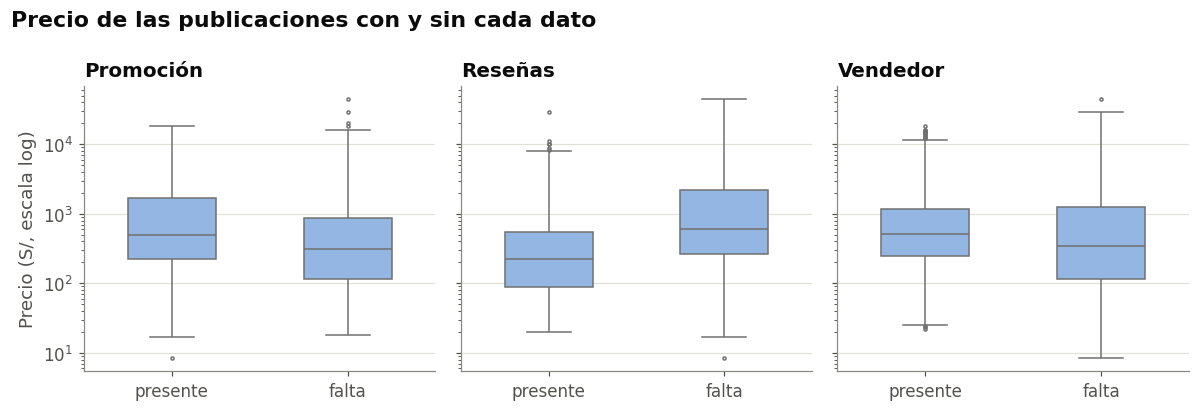

Lectura: Sí. Las publicaciones sin reseñas tienen una mediana de S/ 597 frente a S/ 222 con reseñas: los productos caros se venden menos y acumulan menos opiniones. Imputar la calificación con un promedio asignaría a productos caros la reputación de los baratos.


In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, (columna, titulo) in zip(ejes, [('precio_anterior', 'Promoción'), ('calificacion', 'Reseñas'),
                                        ('vendedor', 'Vendedor')]):
    datos = pd.DataFrame({'precio': ho['precio'], 'dato': np.where(ho[columna].isna(), 'falta', 'presente')})
    sns.boxplot(data=datos, x='dato', y='precio', order=['presente', 'falta'], log_scale=True, width=0.5,
                color='#86b6ef', fliersize=2, ax=ax)
    ax.set(title=titulo, xlabel='', ylabel='Precio (S/, escala log)' if ax is ejes[0] else '')
fig.suptitle('Precio de las publicaciones con y sin cada dato', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
dr = diagnostico.set_index('columna')
guardar_figura(fig, 'f02_precio_segun_faltante',
               '¿El faltante se relaciona con el precio de la publicación?',
               f'Sí. Las publicaciones sin reseñas tienen una mediana de {soles(dr.loc["calificacion", "mediana precio sin dato"])} '
               f'frente a {soles(dr.loc["calificacion", "mediana precio con dato"])} con reseñas: los productos caros se '
               f'venden menos y acumulan menos opiniones. Imputar la calificación con un promedio asignaría a productos '
               f'caros la reputación de los baratos.')

## 3. Tratamiento de los faltantes (FR-008, FR-009)

Eliminar filas está descartado para todas las columnas: ningún faltante es MCAR y borrar sesgaría la muestra
hacia ciertos componentes y precios (U3_T2). Cada columna recibe la estrategia que corresponde a su tipo, y
toda imputación queda marcada:

| Campo | Estrategia del curso | Resultado |
| --- | --- | --- |
| `etiqueta_texto` | eliminar la columna | se retira |
| Promoción | estimar e imputar por estructura | `tiene_descuento`; `descuento_pct` = 0 sin promoción; `precio_anterior` sigue nulo |
| Cuotas | estimar e imputar por estructura | `ofrece_cuotas`; `numero_cuotas` y `monto_cuota` siguen nulos ("no aplica") |
| Reseñas | ignorar | `tiene_resenas`; `calificacion` y `vendidos_min` siguen nulos |
| Vendedor | ignorar, con categoría explícita | `vendedor_visible`; `vendedor` = "no informado" |
| Envío | ignorar, con categoría explícita | `envio` = "no informado" |

Antes, se corrigen las inconsistencias de promoción registradas en el notebook 01: si el "precio anterior" no es
mayor que el precio, no hay promoción real y esos campos se tratan como ausentes.

In [6]:
sin_promocion_real = ho['precio_anterior'].notna() & (ho['precio_anterior'] <= ho['precio'])
guardar_evidencia(ho.loc[sin_promocion_real, ['id_oferta', 'componente', 'titulo', 'precio', 'precio_anterior',
                                             'descuento_anunciado_pct']],
                  '02_correcciones.csv', '02', 'precio anterior no mayor que el precio: promoción anulada')
ho.loc[sin_promocion_real, ['precio_anterior', 'descuento_anunciado_pct']] = pd.NA
print('Promociones anuladas por incoherentes:', int(sin_promocion_real.sum()))

ho = ho.drop(columns='etiqueta_texto')
ho['tiene_descuento'] = ho['precio_anterior'].notna()
ho['descuento_pct'] = ((ho['precio_anterior'] - ho['precio']) / ho['precio_anterior'] * 100).fillna(0).round(2)
ho['ofrece_cuotas'] = ho['numero_cuotas'].notna()
ho['tiene_resenas'] = ho['calificacion'].notna() | ho['vendidos_min'].notna()
ho['vendedor_visible'] = ho['vendedor'].notna()
ho['vendedor'] = ho['vendedor'].fillna('no informado')
ho['envio'] = ho['envio'].fillna('no informado')

Promociones anuladas por incoherentes: 8


**Contraste: ¿qué pasaría si se imputara la calificación con la mediana de su componente?** (estrategia 4,
`groupby` + `fillna`, U3_L4). La tabla muestra que la imputación aplana la distribución —baja la desviación
estándar y fabrica cientos de valores idénticos— y atribuye a los productos sin reseñas una reputación que no se
observó. Por eso se descarta.

In [7]:
imputada = ho['calificacion'].fillna(ho.groupby('componente')['calificacion'].transform('median'))
contraste = pd.DataFrame({
    'observada': ho['calificacion'].describe()[['count', 'mean', 'std']],
    'imputada con mediana': imputada.describe()[['count', 'mean', 'std']],
}).round(3)
contraste.loc['valor más repetido (%)'] = [ho['calificacion'].value_counts(normalize=True).iloc[0] * 100,
                                           imputada.value_counts(normalize=True).iloc[0] * 100]
contraste.round(2)

,observada,imputada con mediana
count,983.00,2715.00
mean,4.78,4.78
std,0.18,0.17
valor más repetido (%),31.54,48.40


## 4. Atípicos univariados (FR-010)

El precio tiene cola derecha en todos los componentes (el promedio supera a la mediana), así que los criterios
se aplican sobre `log10(precio)` y **por componente**: una laptop de S/ 5 000 es normal y un mouse de S/ 5 000
no. Criterios: fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]` o `|z| > 3`.

In [8]:
ho['log_precio'] = np.log10(ho['precio'])
grupo = ho.groupby('componente')['log_precio']
q1, q3 = grupo.transform(lambda s: s.quantile(0.25)), grupo.transform(lambda s: s.quantile(0.75))
z = (ho['log_precio'] - grupo.transform('mean')) / grupo.transform('std')
ho['atipico_iqr'] = (ho['log_precio'] < q1 - 1.5 * (q3 - q1)) | (ho['log_precio'] > q3 + 1.5 * (q3 - q1))
ho['atipico_z'] = z.abs() > 3
resumen_uni = (ho.groupby('componente')[['atipico_iqr', 'atipico_z']].sum().astype(int)
               .reindex(comun.ORDEN_COMPONENTES))
resumen_uni['límite inferior IQR'] = (10 ** (q1 - 1.5 * (q3 - q1))).groupby(ho['componente']).first().round(0)
resumen_uni['límite superior IQR'] = (10 ** (q3 + 1.5 * (q3 - q1))).groupby(ho['componente']).first().round(0)
resumen_uni

,atipico_iqr,atipico_z,límite inferior IQR,límite superior IQR
componente,,,,
laptop,1,1,873.0,26992.0
monitor,4,1,106.0,5586.0
silla,16,9,79.0,3167.0
teclado,10,0,24.0,1824.0
mouse,0,0,4.0,3035.0
audifonos,5,0,12.0,2333.0


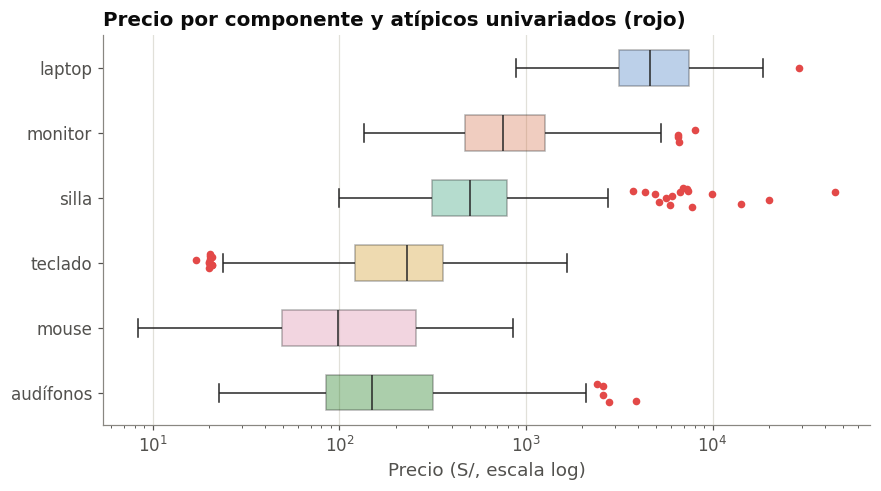

Lectura: Se detectan 36 atípicos univariados; 16 son sillas de oficina de gama alta (marcas como Steelcase, de hasta S/ 45 499). Los demás son audífonos y monitores de gama alta, minitecladas muy baratas y una sola laptop. La revisión de títulos muestra que casi todos son productos reales: la escala logarítmica y las medianas los absorben sin necesidad de eliminarlos.


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.6))
orden = comun.ORDEN_COMPONENTES
sns.boxplot(data=ho, y='componente', x='precio', order=orden, log_scale=True, whis=1.5, width=0.55,
            hue='componente', palette=comun.COLOR_COMPONENTE, legend=False, fliersize=0, ax=ax,
            boxprops={'alpha': 0.35})
atipicos_uni = ho[ho['atipico_iqr'] | ho['atipico_z']]
sns.stripplot(data=atipicos_uni, y='componente', x='precio', order=orden, color=comun.ACENTO, size=5,
              jitter=0.15, ax=ax)
ax.set(title='Precio por componente y atípicos univariados (rojo)', xlabel='Precio (S/, escala log)', ylabel='')
ax.set_yticks(range(len(orden)), [c.replace('audifonos', 'audífonos') for c in orden])
guardar_figura(fig, 'f02_atipicos_univariados',
               '¿Qué precios se alejan de lo habitual en cada componente?',
               f'Se detectan {len(atipicos_uni)} atípicos univariados; {int(resumen_uni.loc["silla", "atipico_iqr"])} son '
               f'sillas de oficina de gama alta (marcas como Steelcase, de hasta '
               f'{soles(atipicos_uni.loc[atipicos_uni["componente"] == "silla", "precio"].max())}). Los demás son '
               f'audífonos y monitores de gama alta, minitecladas muy baratas y una sola laptop. La revisión de títulos '
               f'muestra que casi todos son productos reales: la escala logarítmica y las medianas los absorben sin '
               f'necesidad de eliminarlos.')

## 5. Atípicos bivariados (FR-011)

Dos relaciones deben cumplirse: el precio anterior es mayor que el precio (por encima de la diagonal) y el total
de las cuotas "sin interés" es igual al precio. La segunda se cumple en todas las publicaciones (notebook 01:
cero inconsistencias). La primera se muestra abajo: los puntos sobre la diagonal ya se anularon como promoción
en la sección 3; aquí se observan además descuentos extremos.

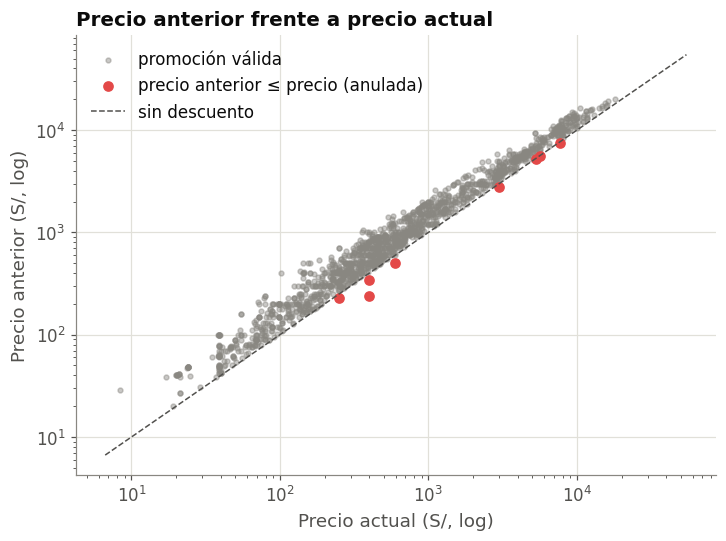

Lectura: Casi todas las promociones están sobre la diagonal, como deben. 8 publicaciones anuncian un "precio anterior" igual o menor que el actual: no son descuentos y se anularon. Ninguna supera un descuento de 74 %, así que no hay descuentos imposibles.


In [10]:
promo = ho[ho['tiene_descuento']]
corregidas = pd.read_csv(comun.EVIDENCIA / '02_correcciones.csv')
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(promo['precio'], promo['precio_anterior'], s=10, color=comun.TINTA_TENUE, alpha=0.45,
           label='promoción válida')
ax.scatter(corregidas['precio'], corregidas['precio_anterior'], s=36, color=comun.ACENTO,
           label='precio anterior ≤ precio (anulada)')
limites = [ho['precio'].min() * 0.8, ho['precio'].max() * 1.2]
ax.plot(limites, limites, color=comun.TINTA_SECUNDARIA, linewidth=1, linestyle='--', label='sin descuento')
ax.set(xscale='log', yscale='log', title='Precio anterior frente a precio actual',
       xlabel='Precio actual (S/, log)', ylabel='Precio anterior (S/, log)')
ax.legend(loc='upper left')
descuento_max = promo['descuento_pct'].max()
guardar_figura(fig, 'f02_bivariado_promocion',
               '¿Son coherentes los precios anteriores que anuncian las promociones?',
               f'Casi todas las promociones están sobre la diagonal, como deben. {len(corregidas)} publicaciones anuncian un '
               f'"precio anterior" igual o menor que el actual: no son descuentos y se anularon. Ninguna supera un '
               f'descuento de {descuento_max:.0f} %, así que no hay descuentos imposibles.')

## 6. Atípicos multivariados (FR-011)

Se combinan tres variables de cobertura completa —log del precio, descuento y posición en los resultados— y se
agrupan con **K-Means** dentro de cada componente, sobre variables estandarizadas (U3_L5, U4_L1). Una
publicación es atípica multivariada si queda a una distancia de su centroide mayor que el percentil 99, o si cae
en un grupo con menos del 1 % de las publicaciones. Como contraste se calcula la **distancia de Mahalanobis**
con el umbral de chi-cuadrado al 99,9 %.

In [11]:
TARJETAS_POR_PAGINA = int(ho['posicion_pagina'].max())
ho['posicion_global'] = (ho['pagina'] - 1) * TARJETAS_POR_PAGINA + ho['posicion_pagina']
VARIABLES_MV = ['log_precio', 'descuento_pct', 'posicion_global']
ho['atipico_kmeans'] = False
ho['atipico_mahalanobis'] = False
for componente, indices in ho.groupby('componente').groups.items():
    x = StandardScaler().fit_transform(ho.loc[indices, VARIABLES_MV])
    modelo = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA).fit(x)
    distancia = np.linalg.norm(x - modelo.cluster_centers_[modelo.labels_], axis=1)
    tamano = pd.Series(modelo.labels_).map(pd.Series(modelo.labels_).value_counts(normalize=True)).to_numpy()
    ho.loc[indices, 'atipico_kmeans'] = (distancia > np.percentile(distancia, 99)) | (tamano < 0.01)
    # Variable que más aleja cada publicación de su centroide: explica por qué es atípica.
    ho.loc[indices, 'rasgo_mv'] = np.array(VARIABLES_MV)[np.abs(x - modelo.cluster_centers_[modelo.labels_]).argmax(axis=1)]
    centrado = x - x.mean(axis=0)
    d2 = np.einsum('ij,jk,ik->i', centrado, np.linalg.pinv(np.cov(x, rowvar=False)), centrado)
    ho.loc[indices, 'atipico_mahalanobis'] = d2 > chi2.ppf(0.999, df=len(VARIABLES_MV))

acuerdo = pd.crosstab(ho['atipico_kmeans'], ho['atipico_mahalanobis'], rownames=['K-Means'],
                      colnames=['Mahalanobis'])
acuerdo

Mahalanobis,False,True
K-Means,,
False,2686,0
True,25,4


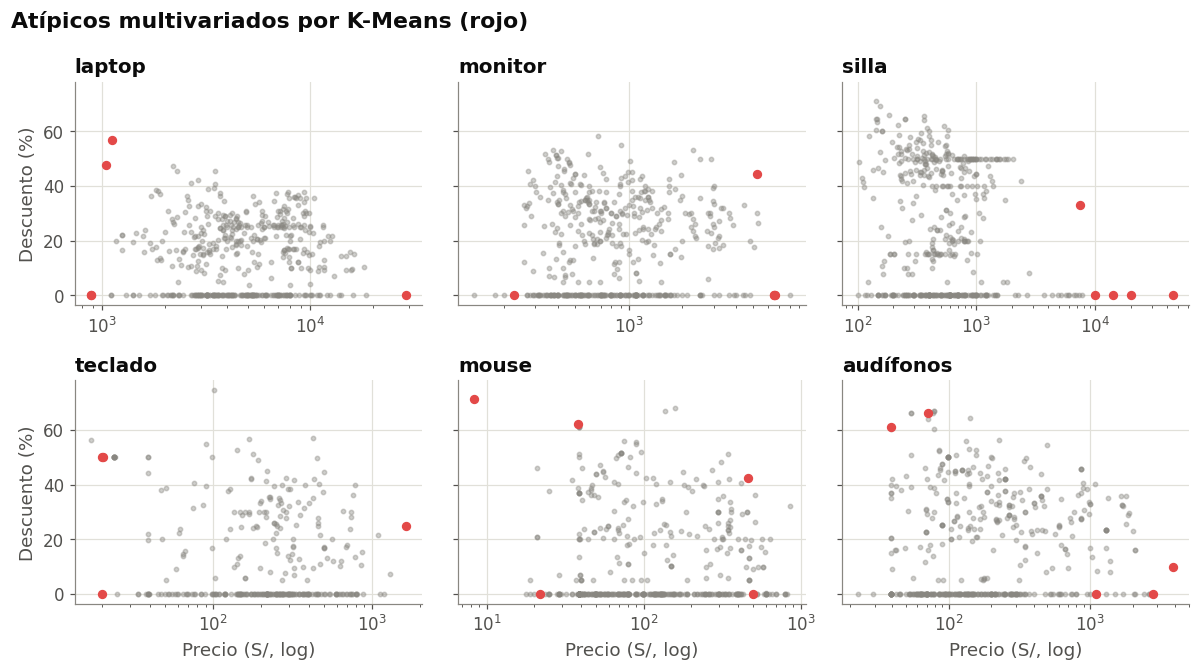

Lectura: K-Means marca 29 publicaciones y Mahalanobis coincide en 4. En 18 el rasgo que más las aleja de su grupo es el precio y en 11, la posición: son, sobre todo, productos de gama alta que el sitio muestra al final de los resultados (posición mediana 594 frente a 352), y 4 ofertas baratas con descuentos de 40 % o más en los primeros 100 puestos. Son combinaciones poco frecuentes, no valores imposibles: se marcan y se conservan.


In [12]:
fig, ejes = plt.subplots(2, 3, figsize=(11, 6.2), sharey=True)
for ax, componente in zip(ejes.flat, comun.ORDEN_COMPONENTES):
    g = ho[ho['componente'] == componente]
    ax.scatter(g['precio'], g['descuento_pct'], s=8, color=comun.TINTA_TENUE, alpha=0.4)
    a = g[g['atipico_kmeans']]
    ax.scatter(a['precio'], a['descuento_pct'], s=26, color=comun.ACENTO)
    ax.set(xscale='log', title=componente.replace('audifonos', 'audífonos'), xlabel='Precio (S/, log)' if componente in ('teclado', 'mouse', 'audifonos') else '',
           ylabel='Descuento (%)' if componente in ('laptop', 'teclado') else '')
fig.suptitle('Atípicos multivariados por K-Means (rojo)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
n_mv = int(ho['atipico_kmeans'].sum())
coinciden = int((ho['atipico_kmeans'] & ho['atipico_mahalanobis']).sum())
mv, resto = ho[ho['atipico_kmeans']], ho[~ho['atipico_kmeans']]
rasgos = mv['rasgo_mv'].value_counts()
baratas_arriba = int(((mv['posicion_global'] <= 100) & (mv['descuento_pct'] >= 40)).sum())
guardar_figura(fig, 'f02_atipicos_multivariados',
               '¿Hay publicaciones anómalas por la combinación de precio, descuento y posición?',
               f'K-Means marca {n_mv} publicaciones y Mahalanobis coincide en {coinciden}. En '
               f'{rasgos.get("log_precio", 0)} el rasgo que más las aleja de su grupo es el precio y en '
               f'{rasgos.get("posicion_global", 0)}, la posición: son, sobre todo, productos de gama alta que el sitio '
               f'muestra al final de los resultados (posición mediana {mv["posicion_global"].median():.0f} frente a '
               f'{resto["posicion_global"].median():.0f}), y {baratas_arriba} ofertas baratas con descuentos de 40 % o más '
               f'en los primeros 100 puestos. Son combinaciones poco frecuentes, no valores imposibles: se marcan y se '
               f'conservan.')

## 7. Decisión sobre cada atípico (FR-012)

Los cuatro tratamientos del curso son no hacer nada, reemplazar, transformar o eliminar (U3_T3). Solo se elimina
un **error comprobable**, definido de antemano en el spec:

- un precio de relleno de cinco o más nueves (99 999, 999 999…). Con menos nueves la regla eliminaría productos
  reales: en esta muestra hay monitores, sillas y audífonos de S/ 999 y una MacBook Pro de S/ 9 999;
- un precio incoherente con el propio financiamiento de la publicación (cero casos: las cuotas cuadran);
- un precio que el título contradice: una laptop de gama de entrada —8 GB de RAM o menos según el título— con un
  precio por encima del percentil 99 de las laptops.

Los demás atípicos son extremos plausibles: se **conservan**, se marcan en `atipico_precio` y el análisis usa
escala logarítmica, medianas y rangos intercuartílicos, que no se dejan arrastrar por ellos (transformación).

In [13]:
ram = pd.to_numeric(ho['titulo'].str.lower().str.extract(r'\b(\d{1,2})\s?gb(?:\s?de)?\s?ram|\b(\d{1,2})\s?gb\b',
                                                           expand=True).bfill(axis=1)[0], errors='coerce')
p99_laptop = ho.loc[ho['componente'] == 'laptop', 'precio'].quantile(0.99)
reglas_error = {
    'precio de relleno': ho['precio'].astype(int).astype(str).str.fullmatch(r'9{5,}'),
    'laptop de 8 GB o menos sobre el percentil 99 del componente': (ho['componente'].eq('laptop') & ram.le(8)
                                                                     & ho['precio'].gt(p99_laptop)),
}
error = pd.Series(False, index=ho.index)
motivo_error = pd.Series('', index=ho.index)
for motivo, mascara in reglas_error.items():
    nuevos = mascara & ~error
    motivo_error[nuevos] = motivo
    error |= mascara
excluidos_error = ho.loc[error]
print(f'Percentil 99 de las laptops: {soles(p99_laptop)}')
excluidos_error[['id_oferta', 'componente', 'titulo', 'precio']]

Percentil 99 de las laptops: S/ 15 879


,id_oferta,componente,titulo,precio
250,MPE959377798,laptop,Lenovo V15 G4 Ryzen 7300u 8gb Ram 1tb Ssd + 1t...,29000.0


In [14]:
ho['atipico_precio'] = (ho['atipico_iqr'] | ho['atipico_z']) & ~error
marcados = ho[ho['atipico_iqr'] | ho['atipico_z'] | ho['atipico_kmeans'] | ho['atipico_mahalanobis']].copy()
marcados['decision'] = np.where(error[marcados.index], 'excluir: error comprobable', 'conservar: extremo plausible')
criterios = marcados[['atipico_iqr', 'atipico_z', 'atipico_kmeans', 'atipico_mahalanobis']]
marcados['criterios'] = criterios.apply(lambda f: ', '.join(c.replace('atipico_', '') for c in f.index[f]), axis=1)
guardar_evidencia(marcados[['id_oferta', 'componente', 'titulo', 'precio', 'descuento_pct', 'criterios', 'decision']],
                  '02_atipicos.csv', '02', 'atípico detectado')
guardar_evidencia(excluidos_error[['id_oferta', 'componente', 'titulo', 'precio']].assign(regla=motivo_error[error]),
                  '02_excluidos_por_error.csv', '02', 'error comprobable')
print(marcados['decision'].value_counts().to_string())

decision
conservar: extremo plausible    50
excluir: error comprobable       1


## 8. Exportación y verificación

In [15]:
tratado = ho.loc[~error].drop(columns=['atipico_iqr', 'atipico_z', 'atipico_kmeans', 'atipico_mahalanobis', 'rasgo_mv',
                                       'posicion_global']).reset_index(drop=True)

assert tratado['id_oferta'].is_unique
assert (tratado['tiene_descuento'] == tratado['precio_anterior'].notna()).all(), '`tiene_descuento ⇔ precio_anterior` no nulo'
assert (tratado['ofrece_cuotas'] == tratado['numero_cuotas'].notna()).all(), '`ofrece_cuotas ⇔ numero_cuotas` no nulo'
assert tratado['calificacion'].dropna().between(1, 5).all(), '`1 ≤ calificacion ≤ 5`'
assert tratado['descuento_pct'].between(0, 100, inclusive='left').all(), '`0 ≤ descuento_pct < 100`'
assert tratado[['vendedor', 'envio']].notna().all().all()
registrar_balance('02_homeoffice', N_ENTRADA, len(tratado), errores=int(error.sum()))
escribir_csv(tratado, INTERMEDIO / '02_homeoffice_tratado.csv')

registrar('faltantes',
          diagnostico={f['columna']: {'pct': f['% faltante'], 'p_componente': f['p_componente'],
                                      'p_pagina': f['p_página'], 'p_anuncio': f['p_anuncio'],
                                      'mediana_con': f['mediana precio con dato'],
                                      'mediana_sin': f['mediana precio sin dato']} for f in filas},
          promociones_anuladas=int(sin_promocion_real.sum()),
          contraste_calificacion={'std_observada': contraste.loc['std', 'observada'],
                                  'std_imputada': contraste.loc['std', 'imputada con mediana'],
                                  'moda_pct_imputada': contraste.loc['valor más repetido (%)', 'imputada con mediana']})
registrar('atipicos', univariados=len(atipicos_uni), kmeans=n_mv, mahalanobis=int(ho['atipico_mahalanobis'].sum()),
          coinciden=coinciden, excluidos_por_error=int(error.sum()), conservados_marcados=int(tratado['atipico_precio'].sum()),
          p99_laptop=p99_laptop, por_componente=resumen_uni['atipico_iqr'].to_dict())
print('02_homeoffice_tratado.csv:', tratado.shape)

02_homeoffice_tratado.csv: (2714, 26)


## Resultado de la etapa

- Ningún faltante es MCAR. Promoción y cuotas faltan por estructura (MNAR): se convirtieron en indicadores y en
  un descuento de 0 % marcado. Reseñas, vendedor y envío son MAR: no se imputan y se marcan.
- Imputar la calificación con la mediana se descartó: deforma la distribución.
- Los atípicos univariados, bivariados y multivariados se detectaron y revisaron; solo se excluyó el error
  comprobable y el resto se conserva marcado.
- El balance de registros cuadra.